In [15]:
import pandas as pd

data = pd.read_csv("lung_cancer.csv")

data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [16]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    str  
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    str  
dtypes

In [17]:
data = data.replace({"M": 1, "F": 0})
data = data.replace({"YES": 1, "NO": 0})

data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0


In [18]:
X = data.drop("LUNG_CANCER", axis=1)
y = data["LUNG_CANCER"]

print("Input columns:", X.shape[1])
print("Target values:", y.unique())

Input columns: 15
Target values: [1 0]


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (247, 15)
Testing data: (62, 15)


In [20]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

ValueError: Unknown label type: unknown. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [ ]:
# Make sure all input values are numeric
X = data.drop("LUNG_CANCER", axis=1)
X = X.apply(pd.to_numeric, errors="coerce")

# Make sure the target is numeric
y = pd.to_numeric(data["LUNG_CANCER"], errors="coerce")

# Remove any invalid rows
valid = X.notna().all(axis=1) & y.notna()
X = X[valid]
y = y[valid].astype(int)

# Split the data again
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
import numpy as np

print("LUNG CANCER PREDICTION SYSTEM")
print("--------------------------------")

gender = int(input("Gender (Male=1, Female=0): "))
age = int(input("Age: "))
smoking = int(input("Smoking (1=No, 2=Yes): "))
yellow_fingers = int(input("Yellow Fingers (1=No, 2=Yes): "))
anxiety = int(input("Anxiety (1=No, 2=Yes): "))
peer_pressure = int(input("Peer Pressure (1=No, 2=Yes): "))
chronic_disease = int(input("Chronic Disease (1=No, 2=Yes): "))
fatigue = int(input("Fatigue (1=No, 2=Yes): "))
allergy = int(input("Allergy (1=No, 2=Yes): "))
wheezing = int(input("Wheezing (1=No, 2=Yes): "))
alcohol = int(input("Alcohol Consuming (1=No, 2=Yes): "))
coughing = int(input("Coughing (1=No, 2=Yes): "))
shortness = int(input("Shortness of Breath (1=No, 2=Yes): "))
swallowing = int(input("Swallowing Difficulty (1=No, 2=Yes): "))
chest_pain = int(input("Chest Pain (1=No, 2=Yes): "))

patient = np.array([[
    gender, age, smoking, yellow_fingers, anxiety,
    peer_pressure, chronic_disease, fatigue, allergy,
    wheezing, alcohol, coughing, shortness,
    swallowing, chest_pain
]])

prediction = model.predict(patient)[0]

print("\n--------------------------------")
if prediction == 1:
    print("Prediction: LUNG CANCER = YES")
else:
    print("Prediction: LUNG CANCER = NO")
print("--------------------------------")

In [ ]:
# Test the model with one patient
patient_df = pd.DataFrame(patient, columns=X.columns)

prediction = model.predict(patient_df)[0]

print("------------------------------")
if prediction == 1:
    print("Prediction: LUNG CANCER = YES")
else:
    print("Prediction: LUNG CANCER = NO")
print("------------------------------")

In [ ]:
# MODEL EVALUATION

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("===================================")
print("       MODEL EVALUATION")
print("===================================")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [24]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [23]:
# Clean target and recreate training/testing data

data["LUNG_CANCER"] = data["LUNG_CANCER"].replace({
    "YES": 1,
    "NO": 0,
    "1": 1,
    "0": 0
}).astype(int)

X = data.drop("LUNG_CANCER", axis=1)
y = data["LUNG_CANCER"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Target values:", y.unique())

Training data: (247, 15)
Testing data: (62, 15)
Target values: [1 0]


In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("========== MODEL EVALUATION ==========")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

========== MODEL EVALUATION ==========
Accuracy: 91.94%

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.75      0.71         8
           1       0.96      0.94      0.95        54

    accuracy                           0.92        62
   macro avg       0.81      0.85      0.83        62
weighted avg       0.92      0.92      0.92        62

Confusion Matrix:
[[ 6  2]
 [ 3 51]]


In [26]:
# Test the model with a new patient

patient_df = pd.DataFrame(patient, columns=X.columns)

prediction = model.predict(patient_df)[0]

if prediction == 1:
    print("Prediction: LUNG CANCER = YES")
else:
    print("Prediction: LUNG CANCER = NO")

NameError: name 'patient' is not defined

In [27]:
# Create a sample patient

patient = [[
    1,   # Gender: Male
    60,  # Age
    2,   # Smoking: Yes
    2,   # Yellow Fingers: Yes
    2,   # Anxiety: Yes
    2,   # Peer Pressure: Yes
    2,   # Chronic Disease: Yes
    2,   # Fatigue: Yes
    2,   # Allergy: Yes
    2,   # Wheezing: Yes
    2,   # Alcohol Consuming: Yes
    2,   # Coughing: Yes
    2,   # Shortness of Breath: Yes
    2,   # Swallowing Difficulty: Yes
    2    # Chest Pain: Yes
]]

patient_df = pd.DataFrame(patient, columns=X.columns)

prediction = model.predict(patient_df)[0]

print("--------------------------------")
if prediction == 1:
    print("Prediction: LUNG CANCER = YES")
else:
    print("Prediction: LUNG CANCER = NO")
print("--------------------------------")

--------------------------------
Prediction: LUNG CANCER = YES
--------------------------------


In [28]:
# Prediction probability

probability = model.predict_proba(patient_df)[0]

print("--------------------------------")
print("LUNG CANCER PREDICTION")
print("--------------------------------")

if prediction == 1:
    print("Prediction: YES")
else:
    print("Prediction: NO")

print(f"Probability of YES: {probability[1] * 100:.2f}%")
print(f"Probability of NO: {probability[0] * 100:.2f}%")

print("--------------------------------")
print("NOTE: This is an ML prediction, not a medical diagnosis.")

--------------------------------
LUNG CANCER PREDICTION
--------------------------------
Prediction: YES
Probability of YES: 100.00%
Probability of NO: 0.00%
--------------------------------
NOTE: This is an ML prediction, not a medical diagnosis.


In [29]:
# Interactive Lung Cancer Prediction

print("================================")
print("   LUNG CANCER PREDICTION")
print("================================")
print("Enter 1 = No, 2 = Yes\n")

gender = int(input("Gender (Male=1, Female=0): "))
age = int(input("Age: "))
smoking = int(input("Smoking: "))
yellow_fingers = int(input("Yellow Fingers: "))
anxiety = int(input("Anxiety: "))
peer_pressure = int(input("Peer Pressure: "))
chronic_disease = int(input("Chronic Disease: "))
fatigue = int(input("Fatigue: "))
allergy = int(input("Allergy: "))
wheezing = int(input("Wheezing: "))
alcohol = int(input("Alcohol Consuming: "))
coughing = int(input("Coughing: "))
shortness = int(input("Shortness of Breath: "))
swallowing = int(input("Swallowing Difficulty: "))
chest_pain = int(input("Chest Pain: "))

new_patient = [[
    gender, age, smoking, yellow_fingers, anxiety,
    peer_pressure, chronic_disease, fatigue, allergy,
    wheezing, alcohol, coughing, shortness,
    swallowing, chest_pain
]]

new_patient_df = pd.DataFrame(new_patient, columns=X.columns)

prediction = model.predict(new_patient_df)[0]
probability = model.predict_proba(new_patient_df)[0]

print("\n================================")
print("        RESULT")
print("================================")

if prediction == 1:
    print("Prediction: YES")
else:
    print("Prediction: NO")

print(f"Probability YES: {probability[1] * 100:.2f}%")
print(f"Probability NO: {probability[0] * 100:.2f}%")

print("================================")
print("For educational purposes only.")
print("Not a medical diagnosis.")

   LUNG CANCER PREDICTION
Enter 1 = No, 2 = Yes



Gender (Male=1, Female=0):  1
Age:  60
Smoking:  1
Yellow Fingers:  1
Anxiety:  1
Peer Pressure:  1
Chronic Disease:  1
Fatigue:  1
Allergy:  1
Wheezing:  1
Alcohol Consuming:  1
Coughing:  1
Shortness of Breath:  1
Swallowing Difficulty:  1
Chest Pain:  1



        RESULT
Prediction: YES
Probability YES: 51.00%
Probability NO: 49.00%
For educational purposes only.
Not a medical diagnosis.


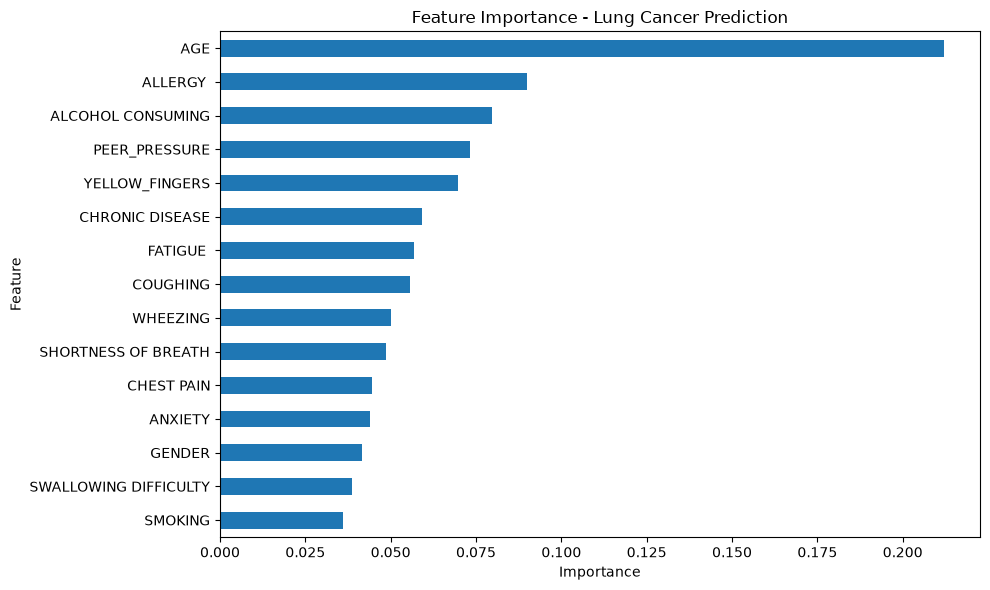

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind="barh")
plt.title("Feature Importance - Lung Cancer Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

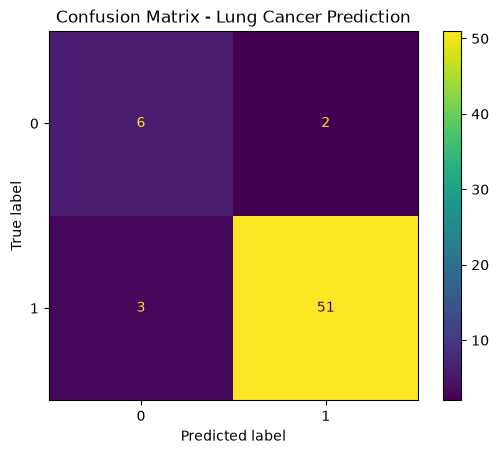

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Confusion Matrix - Lung Cancer Prediction")
plt.show()

In [32]:
import joblib

joblib.dump(model, "lung_cancer_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [33]:
print("===================================")
print("   LUNG CANCER PREDICTION SYSTEM")
print("===================================")

print("Model: Random Forest")
print("Accuracy: 91.94%")
print()
print("The model is ready for prediction.")
print("===================================")

   LUNG CANCER PREDICTION SYSTEM
Model: Random Forest
Accuracy: 91.94%

The model is ready for prediction.


In [34]:
# Final Patient Prediction Interface

print("==========================================")
print("       LUNG CANCER PREDICTION")
print("==========================================")
print("Enter 1 = Yes, 0 = No")
print()

gender = int(input("Gender (Male=1, Female=0): "))
age = int(input("Age: "))
smoking = int(input("Smoking: "))
yellow_fingers = int(input("Yellow Fingers: "))
anxiety = int(input("Anxiety: "))
peer_pressure = int(input("Peer Pressure: "))
chronic_disease = int(input("Chronic Disease: "))
fatigue = int(input("Fatigue: "))
allergy = int(input("Allergy: "))
wheezing = int(input("Wheezing: "))
alcohol = int(input("Alcohol Consuming: "))
coughing = int(input("Coughing: "))
shortness = int(input("Shortness of Breath: "))
swallowing = int(input("Swallowing Difficulty: "))
chest_pain = int(input("Chest Pain: "))

patient = [[
    gender, age, smoking, yellow_fingers, anxiety,
    peer_pressure, chronic_disease, fatigue, allergy,
    wheezing, alcohol, coughing, shortness,
    swallowing, chest_pain
]]

patient_df = pd.DataFrame(patient, columns=X.columns)

prediction = model.predict(patient_df)[0]
probability = model.predict_proba(patient_df)[0]

print()
print("==========================================")
print("                 RESULT")
print("==========================================")

if prediction == 1:
    print("Prediction: YES")
else:
    print("Prediction: NO")

print(f"Probability YES: {probability[1] * 100:.2f}%")
print(f"Probability NO: {probability[0] * 100:.2f}%")

print("==========================================")
print("For educational purposes only.")
print("Not a medical diagnosis.")

       LUNG CANCER PREDICTION
Enter 1 = Yes, 0 = No



Gender (Male=1, Female=0):  1
Age:  60
Smoking:  1
Yellow Fingers:  1
Anxiety:  1
Peer Pressure:  1
Chronic Disease:  1
Fatigue:  1
Allergy:  1
Wheezing:  1
Alcohol Consuming:  1
Coughing:  1
Shortness of Breath:  1
Swallowing Difficulty:  1
Chest Pain:  1



                 RESULT
Prediction: YES
Probability YES: 51.00%
Probability NO: 49.00%
For educational purposes only.
Not a medical diagnosis.
